# 3 · Measuring the solids

For each solid: scan of the light sheet (3D points in mm), profile `height = 350 − z` relative to the support plane (leveled with a line fitted on the lowest points), and heights compared with the nominal profile of the solids (`lightsheet3d.solids`, derived from the dimensions in the course drawings).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.measure import level_to_plate, measure_peaks
from lightsheet3d.pipeline import PLATE_Z, calibrate_camera, calibrate_light_plane, scan_points
from lightsheet3d.report import compare_profile
from lightsheet3d.solids import SOLIDS as NOMINAL


In [2]:
camera = calibrate_camera(DATA / "camera_calibration")
lp = calibrate_light_plane(DATA / "light_plane_calibration", camera.model)

# drawing: peak height (mm) and flank inclination (degrees, left/right) = 180° - dimensioned outer angle
SOLIDS = {
    "Corpo 6 (30o34)": {"solid": "corpo6", "image": "30o34", "heights": [45, 25, 45], "angles": [(60, 75), (70, 65), (80, 55)]},
    "Corpo 5 (30o3)": {"solid": "corpo5", "image": "30o3", "heights": [35, 30, 45], "angles": None},
}

profiles = {}
for name, s in SOLIDS.items():
    X = scan_points(DATA / "scans" / f"{s['image']}.jpg", camera.model, lp.plane)
    y = X[:, 1]
    profiles[name] = (y, level_to_plate(y, PLATE_Z - X[:, 2]))
    print(f"{name}: {len(X)} 3D points")

Corpo 6 (30o34): 1390 3D points
Corpo 5 (30o3): 1375 3D points


## Profiles

Corpo 6 (30o34): distance from the nominal profile: median 0.55 mm, rms 1.09 mm, 90th percentile 1.52 mm (563 points)


Corpo 5 (30o3): distance from the nominal profile: median 0.62 mm, rms 1.07 mm, 90th percentile 1.87 mm (400 points)


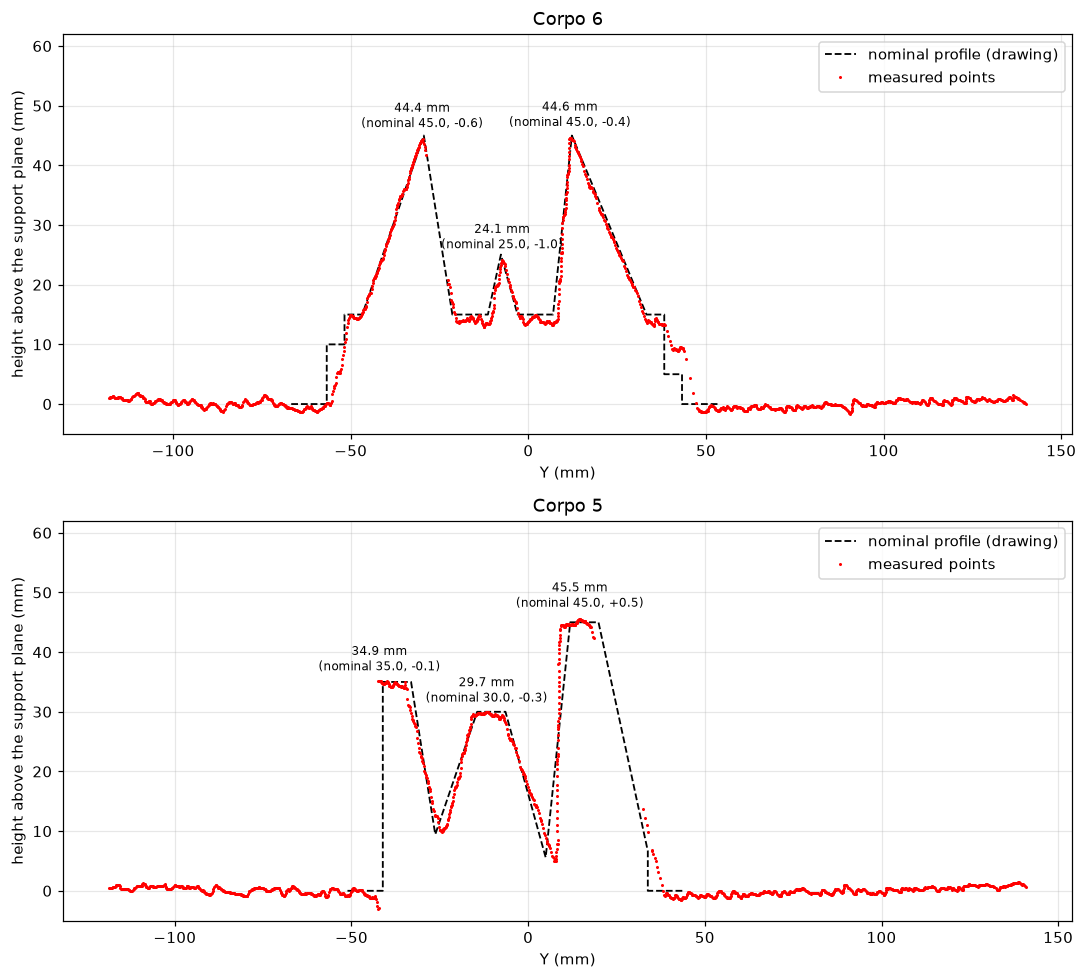

In [3]:
fig, axs = plt.subplots(len(profiles), 1, figsize=(10, 4.5 * len(profiles)))
stats = {}
for ax, (name, (y, h)) in zip(axs, profiles.items()):
    peaks = measure_peaks(y, h, prominence=6, min_separation=10)
    stats[name] = compare_profile(ax, NOMINAL[SOLIDS[name]["solid"]], y, h, peaks)
    print(f"{name}: distance from the nominal profile: median {stats[name]['median']:.2f} mm, rms {stats[name]['rms']:.2f} mm, 90th percentile {stats[name]['p90']:.2f} mm ({stats[name]['points']} points)")
fig.tight_layout(); fig.savefig(FIGURES / "profiles_vs_nominal.png", bbox_inches="tight")

## Measured heights and comparison with the drawing

In [4]:
for name, s in SOLIDS.items():
    y, h = profiles[name]
    peaks = measure_peaks(y, h, prominence=6, min_separation=10)
    print(f"\n{name}")
    print(f"  support base after leveling: {h[np.abs(h) < 3].mean():+.2f} ± {h[np.abs(h) < 3].std():.2f} mm (mean ± std. dev.)")
    errs = []
    for i, p in enumerate(peaks):
        exp = s["heights"][i] if i < len(s["heights"]) else float("nan")
        errs.append(p.height - exp)
        ang = f"flanks L/R {p.left_angle:5.1f}° / {p.right_angle:5.1f}°"
        if s["angles"]: ang += f"  (drawing {s['angles'][i][0]}° / {s['angles'][i][1]}°)"
        print(f"  peak {i + 1}: y = {p.y:6.1f} mm  height {p.height:5.1f} mm  (drawing {exp} mm)  {ang}")
    print(f"  height error: mean {np.nanmean(errs):+.2f} mm, std. dev. {np.nanstd(errs):.2f} mm")


Corpo 6 (30o34)
  support base after leveling: +0.02 ± 0.71 mm (mean ± std. dev.)
  peak 1: y =  -29.9 mm  height  44.4 mm  (drawing 45 mm)  flanks L/R  61.6° /   nan°  (drawing 60° / 75°)
  peak 2: y =   -7.4 mm  height  24.1 mm  (drawing 25 mm)  flanks L/R  71.9° /  61.2°  (drawing 70° / 65°)
  peak 3: y =   11.7 mm  height  44.6 mm  (drawing 45 mm)  flanks L/R  82.8° /  54.8°  (drawing 80° / 55°)
  height error: mean -0.67 mm, std. dev. 0.20 mm

Corpo 5 (30o3)
  support base after leveling: -0.01 ± 0.64 mm (mean ± std. dev.)
  peak 1: y =  -42.1 mm  height  34.9 mm  (drawing 35 mm)  flanks L/R   nan° /  68.6°
  peak 2: y =  -11.7 mm  height  29.7 mm  (drawing 30 mm)  flanks L/R  68.9° /  57.5°
  peak 3: y =   14.6 mm  height  45.5 mm  (drawing 45 mm)  flanks L/R  88.0° /   nan°
  height error: mean +0.03 mm, std. dev. 0.38 mm


## 3D curve and point cloud

Each scan is the 3D curve where the sheet meets the solid: it lies on the plane of the sheet, so it is not a complete scan (the solid or the sheet would have to be moved). The figure shows it above the nominal solid; the points are colored by their distance from the nominal profile. `docs/examples/corpo6_scan.ply` has the same points and colors, and can be opened with MeshLab, CloudCompare or Open3D.

1390 points, median distance 0.54 mm -> docs/examples/corpo6_scan.ply


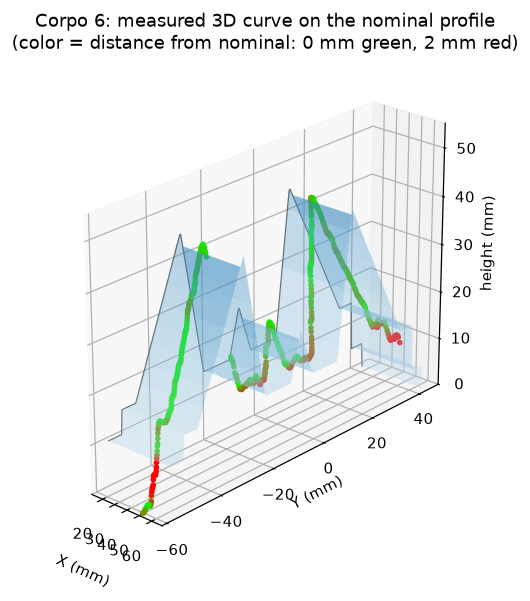

In [5]:
from lightsheet3d.export import distance_colors, write_ply
from lightsheet3d.report import scan_3d
from lightsheet3d.solids import align

name = "Corpo 6 (30o34)"
X = scan_points(DATA / "scans" / "30o34.jpg", camera.model, lp.plane)
h = level_to_plate(X[:, 1], PLATE_Z - X[:, 2])
sign, shift = align(NOMINAL["corpo6"], X[:, 1], h)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
dist = scan_3d(ax, NOMINAL["corpo6"], X, h, sign, shift)
ax.view_init(elev=24, azim=-48); ax.set_title("Corpo 6: measured 3D curve on the nominal profile\n(color = distance from nominal: 0 mm green, 2 mm red)")
fig.savefig(FIGURES / "scan_3d.png", bbox_inches="tight")

(ROOT / "docs" / "examples").mkdir(parents=True, exist_ok=True)
write_ply(ROOT / "docs" / "examples" / "corpo6_scan.ply", np.column_stack([X[:, 0], X[:, 1], h]), distance_colors(dist))
print(f"{len(X)} points, median distance {np.median(dist):.2f} mm -> docs/examples/corpo6_scan.ply")

## Limits of the setup

* **Unlit flanks.** Very steep flanks, or flanks facing away from the sheet, receive no light visible to the camera: in Corpo 6 the right flank of the first peak is missing (`nan`) and the vertical edges have few points. The position and orientation of the solid relative to the sheet determine which parts are measured.
* **Heights.** Error of ~0.5–1 mm on the peaks, with a standard deviation of the base of ~0.8 mm: this is setup noise (master and support not perfectly stable between shots), not reconstruction noise.
* **Sampling.** The points are uniform in `v` (image rows): steep flanks have few points per mm of height and the apex of sharp peaks is underestimated by up to ~0.5 mm.
* **Useful zone.** The master covers a portion of the image; solids taller than `z = 350 mm − 50 mm` fall outside the calibrated volume.